# Pre-Trade Incremental PFE & Limit Utilization

Before a trader can add a swap with a bank, credit has to say yes, and the answer is needed in seconds, not after an overnight simulation. The right question is not how risky the new trade is on its own, but what it does to everything already on the books with that bank. This notebook builds that pre-trade check with a fast model and a statistical guarantee on how often it can be wrong.

**What it does.** It builds the pre-trade credit check a counterparty-risk officer signs off. For a proposed swap it estimates the *incremental* PFE on the bank's netting set in milliseconds, decides whether the trade fits within the limit, and sends it to auto-approval, a full simulation or the credit officer.

Limits, trades and decisions live in SQL tables.

**Data.** Today's SOFR curve and Treasury volatility (U.S. Treasury, FRED), a reference book of SOFR swaps with five banks and their limits, and 4,000 simulated trade requests (synthetic).

**Methods.** Hull–White Monte Carlo with exact incremental revaluation, a LightGBM regression of incremental peak PFE with netting-set features, and split-conformal upper bounds that guarantee the false-approval rate. DuckDB holds the limit database, the utilisation report and the decision log.

**Key output.** A utilisation and headroom report, the decision rule's false-approval and escalation rates compared with the naive stand-alone add-on rule, and a pre-trade dashboard.

## 1. The pre-trade problem

A trader wants to add a swap with Bank C. The question for credit is not "what is this trade's PFE?" but **"what does it do to Bank C's netting-set PFE, and does the result fit within the limit?"**

Because of netting, the two answers can be completely different:

| Situation | Stand-alone PFE of the new trade | Incremental PFE on the netting set |
|---|---|---|
| Trade in the same direction as the book | large | ≈ stand-alone (risk adds up) |
| Trade offsetting the book | large | **negative** (the trade reduces risk) |

A full Monte Carlo per request is accurate but too slow for a trading desk, and the naive stand-alone add-on rejects trades that reduce risk. The workflow built here has three steps:

1. **An instant estimate** of incremental peak PFE from a LightGBM model that sees both the trade and the netting set.
2. **A conformal upper bound** on that estimate, calibrated so that the probability of under-estimating incremental PFE is at most 5%.
3. **A decision:** auto-approve if the bound keeps the netting set within its limit (or the trade reduces exposure). Otherwise run the full engine and, if the limit is breached, escalate to the credit officer.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import duckdb
import lightgbm as lgb
from scipy.optimize import least_squares
from sklearn.metrics import mean_absolute_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

N_PATHS = 2_000
N_REQUESTS = 6_000
DT = 1 / 12
PFE_QUANTILE = 0.975
# fixed seed: the reference swap book is reproducible
SEED = 42
# target probability that the bound under-estimates incremental PFE
CONFORMAL_ALPHA = 0.05
# |incremental PFE| below this is "no change" (e.g. a short trade that ends before the peak)
TOL_MM = 0.05
RATINGS = {
    "Bank A": "AA",
    "Bank B": "A",
    "Bank C": "A",
    "Bank D": "BBB",
    "Bank E": "AA",
}

print(
    f"QuantLib {ql.__version__} · lightgbm {lgb.__version__} · duckdb"
    f" {duckdb.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · lightgbm 4.7.0 · duckdb 1.5.6 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Market data, curve, Hull–White model and the reference swap book

In [3]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)


class DiscountCurve:
    """
    A SOFR discount curve stored as continuous zero rates on a fine daily grid.
    """

    def __init__(self, zero):
        self.zero = np.asarray(zero, dtype=float)
        self.log_df = -self.zero * FINE_T

    def P0(self, t):
        """Discount factor P^M(0, t)."""
        return np.exp(np.interp(t, FINE_T, self.log_df))

    def f0(self, t, h=1e-4):
        """Instantaneous forward rate f^M(0, t)."""
        lo = np.maximum(np.asarray(t) - h, 0)
        return -(np.log(self.P0(np.asarray(t) + h)) - np.log(self.P0(lo))) / (
            np.asarray(t) + h - lo
        )

    def zero_rate(self, t):
        return np.interp(t, FINE_T, self.zero)

    def shifted(self, shift):
        """
        New curve with zero rates moved by `shift` (decimal): a number or an
        array on FINE_T.
        """
        return DiscountCurve(self.zero + shift)


CURVE = DiscountCurve(ust_z + spread_curve)
print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {CURVE.zero_rate(2)*100:.2f}% / 10Y"
    f" {CURVE.zero_rate(10)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


In [4]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
vol_tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, vol_tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    "Hull–White calibrated to 3 years of realised Treasury volatility: a ="
    f" {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr (fit RMSE"
    f" {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

Hull–White calibrated to 3 years of realised Treasury volatility: a = 0.0047, sigma = 86.7 bp/yr (fit RMSE 8.7 bp)


In [5]:
class HullWhite:
    """
    Hull–White 1F (G1++ form): r_t = x_t + phi(t), fitted exactly to `curve`.
    """

    def __init__(self, curve, a, sigma):
        self.curve, self.a, self.sigma = curve, a, sigma

    def B(self, t, T):
        return (1 - np.exp(-self.a * (T - t))) / self.a

    def V(self, t, T):
        a, tau = self.a, T - t
        return (
            self.sigma**2
            / a**2
            * (
                tau
                + 2 / a * np.exp(-a * tau)
                - np.exp(-2 * a * tau) / (2 * a)
                - 3 / (2 * a)
            )
        )

    def simulate(self, times, n_paths, seed):
        """
        Exact OU simulation on any increasing grid that starts at 0; also
        integrates r for SOFR accrual.
        """
        times = np.asarray(times, dtype=float)
        rng = np.random.default_rng(seed)
        x = np.zeros((n_paths, len(times)))
        for j in range(1, len(times)):
            d = times[j] - times[j - 1]
            sd = self.sigma * np.sqrt(
                (1 - np.exp(-2 * self.a * d)) / (2 * self.a)
            )
            x[:, j] = x[:, j - 1] * np.exp(
                -self.a * d
            ) + sd * rng.standard_normal(n_paths)
        phi = (
            self.curve.f0(times)
            + self.sigma**2
            / (2 * self.a**2)
            * (1 - np.exp(-self.a * times)) ** 2
        )
        r = x + phi
        int_r = np.concatenate(
            [
                np.zeros((n_paths, 1)),
                np.cumsum(
                    0.5 * (r[:, 1:] + r[:, :-1]) * np.diff(times), axis=1
                ),
            ],
            axis=1,
        )
        return {
            "times": times,
            "x": x,
            "int_r": int_r,
            "index": {round(t, 8): j for j, t in enumerate(times)},
        }

    def zcb(self, t, T, x_t):
        """
        P(t, T) on every path (x_t: paths) for every maturity in T (m) → paths
        × m.
        """
        T = np.atleast_1d(T)
        P0 = self.curve.P0
        log_a = np.log(P0(T) / P0(t)) + 0.5 * (
            self.V(t, T) - self.V(0.0, T) + self.V(0.0, t)
        )
        return np.exp(log_a[None, :] - np.outer(x_t, self.B(t, T)))


def par_rate(curve, first_pay, n):
    """
    Par fixed rate today for annual payments at first_pay, first_pay+1, ...;
    the part of the current
    period already elapsed accrues at today's SOFR fixing, exactly as in the
    simulation.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        (np.exp(SOFR_TODAY * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return float_leg / curve.P0(pay).sum()


def swap_legs(first_pay, n_pay, hw, sim, dtype=np.float32, cutoff=None):
    """
    Annuity and floating-leg value per unit notional of an annual-fixed vs
    compounded-SOFR swap,
    on every path and simulation date (paths × dates). Value to the fixed
    receiver = K·annuity − float.
    `cutoff` (optional, one time per grid date) drops cash flows paid on or
    before it: used to value at
    t−MPoR only the flows still outstanding at t (both parties keep paying
    during the margin period).
    """
    times, x, int_r, index = sim["times"], sim["x"], sim["int_r"], sim["index"]
    cutoff = times if cutoff is None else np.maximum(cutoff, times)
    pay = first_pay + np.arange(n_pay)
    annuity = np.zeros(x.shape, dtype=dtype)
    float_leg = np.zeros(x.shape, dtype=dtype)
    for j, t in enumerate(times):
        live = pay > cutoff[j] + 1e-9
        if not live.any():
            # matured (or all flows paid by the cutoff)
            continue
        rem = pay[live]
        # start of the accrual period of the next flow
        start = rem[0] - 1.0
        # period starts after t (only with a cutoff)
        if start > t + 1e-9:
            p = hw.zcb(t, np.concatenate([[start], rem]), x[:, j])
            annuity[:, j] = p[:, 1:].sum(axis=1)
            float_leg[:, j] = p[:, 0] - p[:, -1]
            continue
        p = hw.zcb(t, rem, x[:, j])
        accrual = (
            np.exp(int_r[:, j] - int_r[:, index[round(start, 8)]])
            if start >= 0
            else np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        )
        annuity[:, j] = p.sum(axis=1)
        # Compounded SOFR: the running coupon is worth (SOFR accrued so far) −
        # P(t, T_next), because the compounding still to come up to T_next is
        # worth exactly 1 today. Summing the remaining coupons telescopes to:
        # accrued factor − P(t, T_n).
        float_leg[:, j] = accrual - p[:, -1]
    return annuity, float_leg


def revalue_book(book, hw, sim, cutoff=None):
    """
    Values to us (USD mm) of every swap in `book` on every path and date →
    trades × paths × dates.
    """
    out = np.zeros((len(book), *sim["x"].shape), dtype=np.float32)
    for i, tr in enumerate(book.itertuples()):
        ann, flt = swap_legs(tr.first_pay, tr.n_pay, hw, sim, cutoff=cutoff)
        out[i] = tr.omega * (tr.fixed_rate * ann - flt) * tr.notional_mm
    return out


def exposure_metrics(v, times, q=0.975):
    """
    v: paths × monthly dates (USD mm) → EE, ENE, PFE profiles and the Basel
    1-year scalars EPE and EEPE
    (standard definitions: averages over the monthly grid points of the first
    year).
    """
    pos = np.maximum(v, 0)
    ee = pos.mean(axis=0)
    one_year = times <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": np.minimum(v, 0).mean(axis=0),
        "PFE": np.quantile(pos, q, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }

In [6]:
# The reference swap book, generated with a fixed seed and documented rules so
# every number is reproducible
rng = np.random.default_rng(42)
COUNTERPARTIES = ["Bank A", "Bank B", "Bank C", "Bank D", "Bank E"]
PFE_LIMITS = {
    "Bank A": 250,
    "Bank B": 80,
    "Bank C": 150,
    "Bank D": 180,
    "Bank E": 100,
}
trades = []
for i in range(25):
    # next payment in 1–12 months (month-aligned)
    first_pay = rng.integers(1, 13) / 12
    n_pay = int(rng.choice([2, 3, 5, 7, 10, 10, 15, 20, 30]))
    seasoned = rng.random() < 0.6
    k_par = par_rate(CURVE, first_pay, n_pay)
    fixed = k_par + (rng.normal(0, 0.0075) if seasoned else 0.0)
    trades.append({
        "trade_id": f"IRS-{i+1:03d}",
        "counterparty": COUNTERPARTIES[i % 5],
        "direction": rng.choice(["receive fixed", "pay fixed"]),
        "notional_mm": float(rng.choice([25, 50, 100, 150, 250, 400])),
        "first_pay": first_pay,
        "n_pay": n_pay,
        "fixed_rate": fixed,
        "par_rate": k_par,
        "maturity_y": first_pay + n_pay - 1,
    })
book = pd.DataFrame(trades)
book["omega"] = np.where(book["direction"] == "receive fixed", 1.0, -1.0)

# long enough for a new 30-year swap
TIME = np.round(np.arange(0, 30 + DT / 2, DT), 10)
hw = HullWhite(CURVE, A_HW, SIGMA_HW)
sim = hw.simulate(TIME, N_PATHS, seed=SEED + 1)
values = revalue_book(book, hw, sim)
netted = {
    cp: values[(book["counterparty"] == cp).to_numpy()].sum(axis=0)
    for cp in COUNTERPARTIES
}
pfe_prof = {
    cp: np.quantile(np.maximum(v, 0), PFE_QUANTILE, axis=0)
    for cp, v in netted.items()
}
print(
    f"Existing book revalued: {len(book)} swaps × {N_PATHS:,} paths ×"
    f" {len(TIME)} dates"
)

Existing book revalued: 25 swaps × 2,000 paths × 361 dates


## 4. The limit database (DuckDB)

Counterparties, limits, trades and exposures go into SQL tables, as they would in a risk data warehouse. The daily **utilisation report** is a query.

In [7]:
con = duckdb.connect()
cps = pd.DataFrame({
    "counterparty": COUNTERPARTIES,
    "rating": [RATINGS[c] for c in COUNTERPARTIES],
    "pfe_limit_mm": [PFE_LIMITS[c] for c in COUNTERPARTIES],
})
exposures = pd.DataFrame({
    "counterparty": COUNTERPARTIES,
    "peak_pfe_mm": [pfe_prof[c].max() for c in COUNTERPARTIES],
    "peak_pfe_year": [TIME[pfe_prof[c].argmax()] for c in COUNTERPARTIES],
    "mtm_mm": [netted[c][:, 0].mean() for c in COUNTERPARTIES],
    "as_of": EVAL_DATE.date(),
}).astype({"peak_pfe_mm": float, "peak_pfe_year": float, "mtm_mm": float})
trades_tbl = book[[
    "trade_id",
    "counterparty",
    "direction",
    "notional_mm",
    "maturity_y",
    "fixed_rate",
]].copy()
con.register("counterparties", cps)
con.register("exposures", exposures)
con.register("trades", trades_tbl)

utilisation = con.execute("""
    SELECT c.counterparty, c.rating, c.pfe_limit_mm,
           ROUND(e.peak_pfe_mm, 1)                                   AS peak_pfe_mm,
           ROUND(100 * e.peak_pfe_mm / c.pfe_limit_mm, 1)            AS utilisation_pct,
           ROUND(c.pfe_limit_mm - e.peak_pfe_mm, 1)                  AS headroom_mm,
           COUNT(t.trade_id)                                         AS n_trades,
           SUM(t.notional_mm)                                        AS gross_notional_mm,
           CASE WHEN e.peak_pfe_mm > c.pfe_limit_mm THEN 'breach'
                WHEN e.peak_pfe_mm > 0.75 * c.pfe_limit_mm THEN 'watch' ELSE 'within' END AS status
    FROM counterparties c
    JOIN exposures e USING (counterparty)
    LEFT JOIN trades t USING (counterparty)
    GROUP BY ALL
    ORDER BY utilisation_pct DESC
""").df()
utilisation

,counterparty,rating,pfe_limit_mm,peak_pfe_mm,utilisation_pct,headroom_mm,n_trades,gross_notional_mm,status
0,Bank D,BBB,180,204.00,113.40,-24.00,5,"1,000.00",breach
1,Bank A,AA,250,216.60,86.60,33.40,5,725.00,watch
2,Bank E,AA,100,85.40,85.40,14.60,5,525.00,watch
3,Bank C,A,150,102.60,68.40,47.40,5,450.00,within
4,Bank B,A,80,48.20,60.20,31.80,5,"1,250.00",within


## 5. Simulating trade requests and their exact incremental PFE

The candidates are new spot-starting SOFR swaps (1–30 years) with a random bank, direction, size and a small client margin on the fixed rate. A swap's value is linear in notional and fixed rate, so the annuity and floating leg of each tenor are simulated once on the same paths as the book.

Each request's exact effect on its netting set is then a weighted sum followed by a quantile: about 10 ms per request.

In [8]:
TENORS = [1, 2, 3, 5, 7, 10, 12, 15, 20, 25, 30]
legs = {n: swap_legs(1.0, n, hw, sim) for n in TENORS}
par = {n: par_rate(CURVE, 1.0, n) for n in TENORS}
ann0 = {n: float(legs[n][0][0, 0]) for n in TENORS}
standalone_unit = {
    n: np.quantile(
        np.maximum((par[n] * legs[n][0] - legs[n][1]), 0), PFE_QUANTILE, axis=0
    ).max()
    # receiver, per USD 1mm notional
    for n in TENORS
}
standalone_unit_pay = {
    n: np.quantile(
        np.maximum(-(par[n] * legs[n][0] - legs[n][1]), 0),
        PFE_QUANTILE,
        axis=0,
    ).max()
    for n in TENORS
}


def ns_dv01(cp):
    """
    Net DV01 of a netting set (USD mm per bp, receiver positive): notional ×
    today's annuity.
    """
    sub = book[book["counterparty"] == cp]
    return float(
        sum(
            r.omega
            * r.notional_mm
            * CURVE.P0(r.first_pay + np.arange(r.n_pay)).sum()
            for r in sub.itertuples()
        )
        * 1e-4
    )


# USD mm per bp, receiver positive
NS_DV01 = {cp: ns_dv01(cp) for cp in COUNTERPARTIES}
NS_FEATS = {
    cp: {
        "ns_peak_pfe": pfe_prof[cp].max(),
        "ns_peak_year": TIME[pfe_prof[cp].argmax()],
        "ns_utilisation": pfe_prof[cp].max() / PFE_LIMITS[cp],
        "ns_dv01": NS_DV01[cp],
        "ns_mtm": netted[cp][:, 0].mean(),
        "ns_ee_peak": np.maximum(netted[cp], 0).mean(axis=0).max(),
    }
    for cp in COUNTERPARTIES
}

req_rng = np.random.default_rng(SEED + 17)
records = []
t0 = time.perf_counter()
for rid in range(N_REQUESTS):
    cp = COUNTERPARTIES[int(req_rng.integers(5))]
    n = int(req_rng.choice(TENORS))
    omega = float(req_rng.choice([-1.0, 1.0]))
    notional = float(req_rng.choice([25, 50, 100, 150, 250, 400, 500]))
    margin_bp = float(req_rng.normal(0, 10))
    # client pays the margin in either direction
    K = par[n] + margin_bp / 1e4 * omega
    v_new = omega * notional * (K * legs[n][0] - legs[n][1])
    after = np.quantile(
        np.maximum(netted[cp] + v_new, 0), PFE_QUANTILE, axis=0
    )
    sa = (standalone_unit if omega > 0 else standalone_unit_pay)[n] * notional
    trade_dv01 = omega * notional * ann0[n] * 1e-4
    nsf = NS_FEATS[cp]
    t_mid = min(n / 2, 29.9)
    records.append({
        "request_id": rid,
        "counterparty": cp,
        "rating": RATINGS[cp],
        "tenor": n,
        "omega": omega,
        "notional_mm": notional,
        "margin_bp": margin_bp,
        "trade_dv01": trade_dv01,
        "standalone_pfe": sa,
        **nsf,
        "dv01_alignment": np.sign(trade_dv01 * nsf["ns_dv01"]) * min(
            abs(trade_dv01), abs(nsf["ns_dv01"])
        ),
        "dv01_ratio": trade_dv01 / (abs(nsf["ns_dv01"]) + 1e-6),
        "ns_pfe_at_trade_mid": pfe_prof[cp][int(round(t_mid / DT))],
        "ns_pfe_at_trade_end": pfe_prof[cp][
            min(int(round(n / DT)), len(TIME) - 1)
        ],
        "pfe_after": after.max(),
        "incremental_pfe": after.max() - nsf["ns_peak_pfe"],
        "limit": PFE_LIMITS[cp],
    })
requests_df = pd.DataFrame(records)
exact_ms = (time.perf_counter() - t0) / N_REQUESTS * 1e3
print(
    f"{N_REQUESTS:,} requests valued exactly in"
    f" {exact_ms * N_REQUESTS / 1e3:.0f}s ({exact_ms:.1f} ms each) ·"
    f" {(requests_df['incremental_pfe'] < -TOL_MM).mean() * 100:.0f}% reduce"
    " their netting set's peak PFE,"
    f" {(requests_df['incremental_pfe'].abs() <= TOL_MM).mean() * 100:.0f}%"
    " leave it unchanged"
)
requests_df[["standalone_pfe", "incremental_pfe"]].describe().T.round(1)

6,000 requests valued exactly in 70s (11.6 ms each) · 25% reduce their netting set's peak PFE, 38% leave it unchanged


,count,mean,std,min,25%,50%,75%,max
standalone_pfe,"6,000.00",57.40,81.90,0.20,6.50,21.30,67.60,448.40
incremental_pfe,"6,000.00",23.90,76.30,-149.70,-0.00,-0.00,21.80,454.00


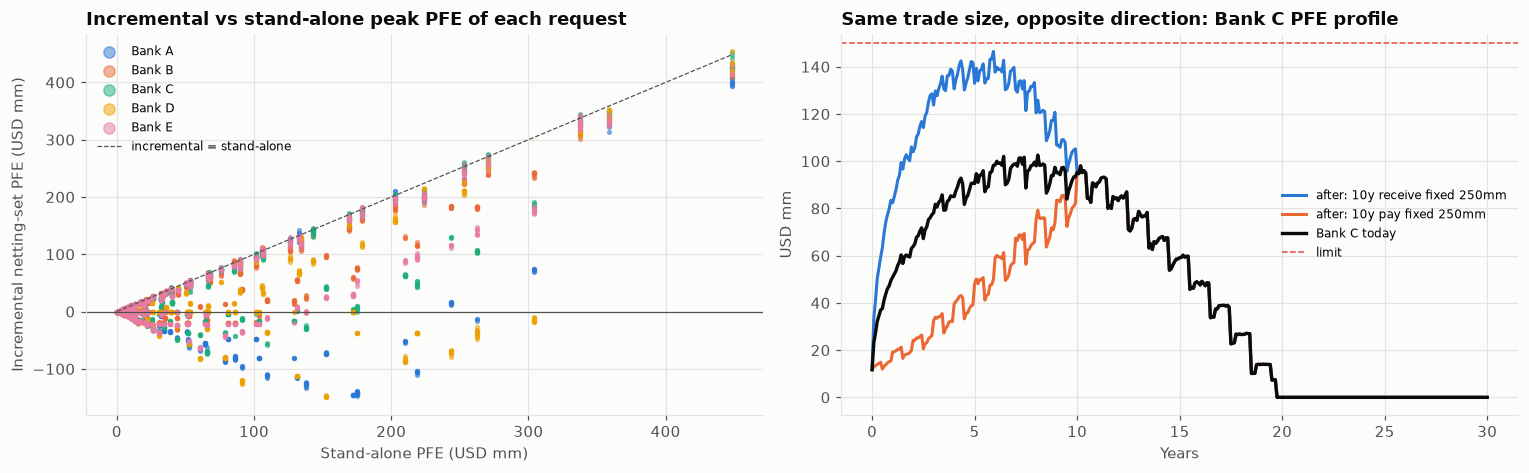

In [9]:
# --- Chart 1: stand-alone vs incremental PFE: netting changes the answer
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
for cp, color in zip(COUNTERPARTIES, PALETTE):
    s = requests_df[requests_df["counterparty"] == cp]
    ax.scatter(
        s["standalone_pfe"],
        s["incremental_pfe"],
        s=6,
        color=color,
        alpha=0.5,
        label=cp,
    )
lim = requests_df["standalone_pfe"].max()
ax.plot(
    [0, lim],
    [0, lim],
    color=INK_2,
    ls="--",
    lw=0.8,
    label="incremental = stand-alone",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Incremental vs stand-alone peak PFE of each request")
ax.set_xlabel("Stand-alone PFE (USD mm)")
ax.set_ylabel("Incremental netting-set PFE (USD mm)")
ax.legend(fontsize=8, markerscale=3)
ax = axes[1]
ex = requests_df[
    (requests_df["counterparty"] == "Bank C")
    & (requests_df["tenor"] == 10)
    & (requests_df["notional_mm"] == 250)
]
for omega, color, name in [
    (1.0, PALETTE[0], "receive fixed"),
    (-1.0, PALETTE[1], "pay fixed"),
]:
    v_new = omega * 250 * (par[10] * legs[10][0] - legs[10][1])
    ax.plot(
        TIME,
        np.quantile(
            np.maximum(netted["Bank C"] + v_new, 0), PFE_QUANTILE, axis=0
        ),
        color=color,
        label=f"after: 10y {name} 250mm",
    )
ax.plot(TIME, pfe_prof["Bank C"], color=INK, lw=2.2, label="Bank C today")
ax.axhline(
    PFE_LIMITS["Bank C"], color=STATUS["red"], ls="--", lw=1, label="limit"
)
ax.set_title("Same trade size, opposite direction: Bank C PFE profile")
ax.set_xlabel("Years")
ax.set_ylabel("USD mm")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_standalone_vs_incremental")
plt.show()

## 6. LightGBM estimate of incremental PFE, with a conformal bound

**Features.** The trade (tenor, direction, notional, margin, DV01, stand-alone PFE) and the netting set (current peak PFE and its timing, utilisation, net DV01, MtM, PFE at the trade's mid-life and maturity). Interaction features (DV01 alignment and ratio) tell the model whether the trade adds to or offsets the book.

**Split conformal bound.** On a calibration set the model's under-estimation is measured relative to trade size, $r=(y-\hat y)/\text{SA}$, where SA is the stand-alone PFE. With $q$ the $(1-\alpha)$ empirical quantile of $r$, the bound $\hat y + q\cdot\text{SA}$ covers the true incremental PFE with probability $\ge 1-\alpha$ on new requests from the same distribution (Vovk; Lei et al., 2018). No distributional assumption is needed, which is what makes it suitable for a control.

In [10]:
FEATURES = [
    "tenor",
    "omega",
    "notional_mm",
    "margin_bp",
    "trade_dv01",
    "standalone_pfe",
    "ns_peak_pfe",
    "ns_peak_year",
    "ns_utilisation",
    "ns_dv01",
    "ns_mtm",
    "ns_ee_peak",
    "dv01_alignment",
    "dv01_ratio",
    "ns_pfe_at_trade_mid",
    "ns_pfe_at_trade_end",
]
split = np.random.default_rng(SEED).permutation(N_REQUESTS)
i_tr, i_cal, i_te = (
    split[: int(0.6 * N_REQUESTS)],
    split[int(0.6 * N_REQUESTS) : int(0.8 * N_REQUESTS)],
    split[int(0.8 * N_REQUESTS) :],
)
tr, cal, te = (
    requests_df.iloc[i_tr],
    requests_df.iloc[i_cal],
    requests_df.iloc[i_te].copy(),
)

model = lgb.LGBMRegressor(
    n_estimators=1_500,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=15,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
)
# Early stopping uses a slice of the *training* set: the calibration set must
# stay untouched by model selection, otherwise its residuals are optimistic and
# the conformal guarantee breaks.
fit_part, val_part = (
    tr.iloc[: int(0.85 * len(tr))],
    tr.iloc[int(0.85 * len(tr)) :],
)
model.fit(
    fit_part[FEATURES],
    fit_part["incremental_pfe"],
    eval_set=[(val_part[FEATURES], val_part["incremental_pfe"])],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
t0 = time.perf_counter()
te["predicted"] = model.predict(te[FEATURES])
ml_ms = (time.perf_counter() - t0) / len(te) * 1e3

r_cal = (cal["incremental_pfe"] - model.predict(cal[FEATURES])) / cal[
    "standalone_pfe"
]
Q_CONF = np.quantile(
    r_cal, np.ceil((len(cal) + 1) * (1 - CONFORMAL_ALPHA)) / len(cal)
)
te["upper_bound"] = te["predicted"] + Q_CONF * te["standalone_pfe"]
coverage = (te["incremental_pfe"] <= te["upper_bound"]).mean() * 100
print(
    f"LightGBM ({model.best_iteration_} trees) on test requests: R²"
    f" {r2_score(te['incremental_pfe'], te['predicted']):.3f} · MAE"
    f" {mean_absolute_error(te['incremental_pfe'], te['predicted']):.2f}mm ·"
    f" {ml_ms:.3f} ms per request (exact engine {exact_ms:.1f} ms) · conformal"
    f" q = {Q_CONF:.3f} × stand-alone · coverage {coverage:.1f}% (target"
    f" {100*(1-CONFORMAL_ALPHA):.0f}%)"
)
pd.Series(model.feature_importances_, index=FEATURES).sort_values(
    ascending=False
).head(8)

LightGBM (1500 trees) on test requests: R² 0.999 · MAE 0.55mm · 0.126 ms per request (exact engine 11.6 ms) · conformal q = 0.074 × stand-alone · coverage 95.6% (target 95%)


dv01_ratio             7899
trade_dv01             6368
standalone_pfe         6279
margin_bp              6255
ns_pfe_at_trade_mid    4488
dv01_alignment         3711
ns_pfe_at_trade_end    3259
tenor                  2629
dtype: int32

## 7. Decision rules compared

A request is **auto-approved** if its estimated post-trade PFE stays within the limit, or if it does not increase the netting set's peak PFE (a risk-reducing trade is accepted even for a bank in breach). Otherwise it is **escalated**: full simulation, then credit-officer review on breach. The rules differ only in the estimate they use:

| Rule | Estimate of incremental PFE |
|---|---|
| Naive add-on | stand-alone PFE (no netting) |
| LightGBM point estimate | $\hat y$ |
| LightGBM + conformal bound | $\hat y + q\cdot\text{SA}$ |
| Exact (the benchmark) | full Monte Carlo |

The key control metric is the **false approval**: a trade auto-approved that in fact takes the netting set over its limit and increases exposure.

In [11]:
te["base_pfe"] = te["ns_peak_pfe"]
truth_ok = (te["pfe_after"] <= te["limit"]) | (te["incremental_pfe"] <= TOL_MM)


def decide(inc):
    return ((te["base_pfe"] + inc) <= te["limit"]) | (inc <= TOL_MM)


RULES = {
    "Naive stand-alone add-on": te["standalone_pfe"],
    "LightGBM point estimate": te["predicted"],
    "LightGBM + conformal bound": te["upper_bound"],
    "Exact Monte Carlo": te["incremental_pfe"],
}
rows = []
for name, inc in RULES.items():
    approve = decide(inc)
    rows.append({
        "rule": name,
        "auto-approved %": approve.mean() * 100,
        "escalated %": (~approve).mean() * 100,
        "false approvals": int((approve & ~truth_ok).sum()),
        "false approval rate %": (approve & ~truth_ok).mean() * 100,
        "needless escalations %": ((~approve) & truth_ok).mean() * 100,
    })
rules = pd.DataFrame(rows).set_index("rule")
te["decision"] = np.where(
    decide(te["upper_bound"]),
    "auto-approve",
    np.where(
        truth_ok,
        "escalate → approved after full simulation",
        "escalate → credit officer",
    ),
)
rules.round(2)

,auto-approved %,escalated %,false approvals,false approval rate %,needless escalations %
rule,,,,,
Naive stand-alone add-on,47.00,53.00,0,0.00,29.08
LightGBM point estimate,72.08,27.92,0,0.00,4.00
LightGBM + conformal bound,63.33,36.67,0,0.00,12.75
Exact Monte Carlo,76.08,23.92,0,0.00,0.00


In [12]:
# --- The decision log in SQL
con.register(
    "requests",
    te[[
        "request_id",
        "counterparty",
        "rating",
        "tenor",
        "omega",
        "notional_mm",
        "standalone_pfe",
        "predicted",
        "upper_bound",
        "incremental_pfe",
        "base_pfe",
        "limit",
        "decision",
    ]],
)
decision_report = con.execute("""
    SELECT counterparty, rating,
           COUNT(*)                                                         AS requests,
           ROUND(100 * AVG(CASE WHEN decision = 'auto-approve' THEN 1 ELSE 0 END), 1)   AS auto_approved_pct,
           ROUND(100 * AVG(CASE WHEN decision LIKE '%credit officer' THEN 1 ELSE 0 END), 1) AS to_credit_officer_pct,
           ROUND(AVG(incremental_pfe), 1)                                   AS avg_incremental_pfe_mm,
           ROUND(MIN(incremental_pfe), 1)                                   AS best_hedge_mm,
           ROUND(100 * AVG(CASE WHEN incremental_pfe < -0.05 THEN 1 ELSE 0 END), 1) AS risk_reducing_pct
    FROM requests
    GROUP BY counterparty, rating
    ORDER BY counterparty
""").df()
top_hedges = con.execute("""
    SELECT request_id, counterparty, tenor, CASE WHEN omega > 0 THEN 'receive' ELSE 'pay' END AS side,
           notional_mm, ROUND(standalone_pfe, 1) AS standalone_pfe_mm, ROUND(incremental_pfe, 1) AS incremental_pfe_mm
    FROM requests ORDER BY incremental_pfe LIMIT 5
""").df()
display(decision_report)
top_hedges

,counterparty,rating,requests,auto_approved_pct,to_credit_officer_pct,avg_incremental_pfe_mm,best_hedge_mm,risk_reducing_pct
0,Bank A,AA,242,80.60,18.20,14.90,-142.70,33.50
1,Bank B,A,237,72.20,25.30,35.30,-27.60,25.30
2,Bank C,A,243,76.10,21.40,29.60,-70.50,18.10
3,Bank D,BBB,217,18.00,19.80,15.10,-147.30,15.70
4,Bank E,AA,261,65.10,33.70,30.90,-43.90,24.10


,request_id,counterparty,tenor,side,notional_mm,standalone_pfe_mm,incremental_pfe_mm
0,325,Bank D,30,pay,250.00,152.10,-147.30
1,4554,Bank A,20,pay,400.00,174.80,-142.70
2,707,Bank A,20,pay,400.00,174.80,-142.50
3,3472,Bank A,20,pay,400.00,174.80,-141.30
4,4416,Bank A,20,pay,400.00,174.80,-138.60


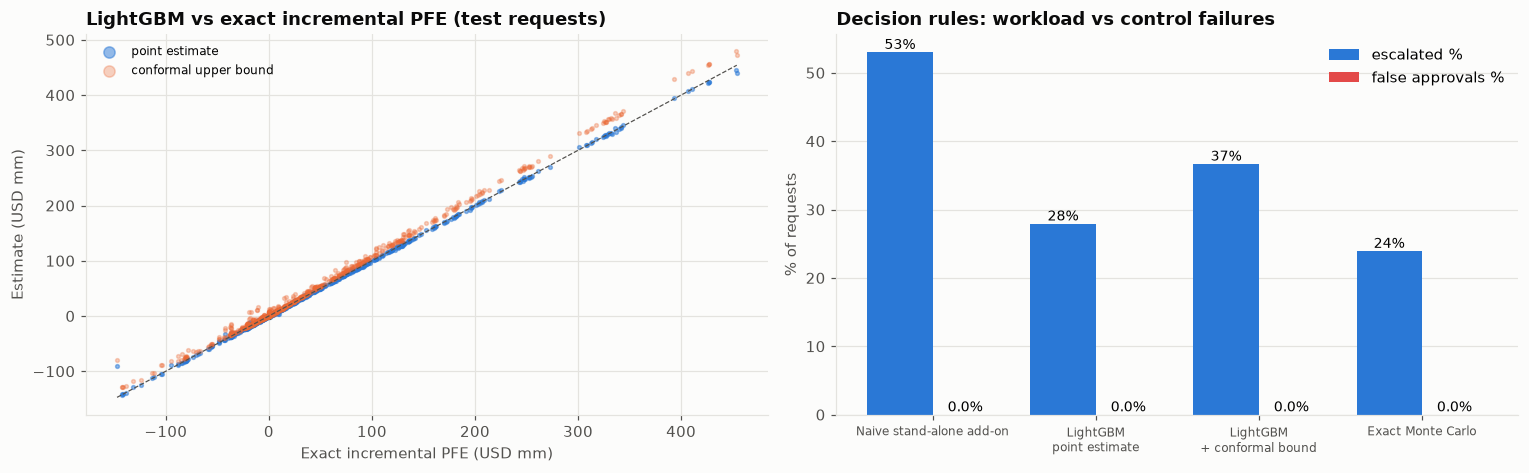

In [13]:
# --- Chart 2: model accuracy and the decision trade-off
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.scatter(
    te["incremental_pfe"],
    te["predicted"],
    s=6,
    color=PALETTE[0],
    alpha=0.5,
    label="point estimate",
)
ax.scatter(
    te["incremental_pfe"],
    te["upper_bound"],
    s=6,
    color=PALETTE[1],
    alpha=0.3,
    label="conformal upper bound",
)
lim = [te["incremental_pfe"].min(), te["incremental_pfe"].max()]
ax.plot(lim, lim, color=INK_2, ls="--", lw=0.8)
ax.set_title("LightGBM vs exact incremental PFE (test requests)")
ax.set_xlabel("Exact incremental PFE (USD mm)")
ax.set_ylabel("Estimate (USD mm)")
ax.legend(fontsize=8, markerscale=3)
ax = axes[1]
x_pos = np.arange(len(rules))
ax.bar(
    x_pos - 0.2,
    rules["escalated %"],
    0.4,
    color=PALETTE[0],
    label="escalated %",
)
ax.bar(
    x_pos + 0.2,
    rules["false approval rate %"],
    0.4,
    color=STATUS["red"],
    label="false approvals %",
)
for xp, (e, f) in zip(
    x_pos, rules[["escalated %", "false approval rate %"]].values
):
    ax.text(xp - 0.2, e, f"{e:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.text(xp + 0.2, f, f"{f:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(
    x_pos,
    [
        r.replace(" + ", "\n+ ").replace("LightGBM ", "LightGBM\n")
        for r in rules.index
    ],
    fontsize=8,
)
ax.set_title("Decision rules: workload vs control failures")
ax.set_ylabel("% of requests")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "02_model_accuracy_and_rules")
plt.show()

## 8. Pre-trade dashboard

In [14]:
status_color = {
    "within": STATUS["green"],
    "watch": STATUS["amber"],
    "breach": STATUS["red"],
}
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.09,
    specs=[[{}, {}], [{"type": "table"}, {"type": "table"}]],
    subplot_titles=(
        "Limit utilisation today",
        "Request routing by counterparty (test set)",
        "Decision rules compared",
        "Utilisation report (SQL)",
    ),
)
dash.add_trace(
    go.Bar(
        x=utilisation["counterparty"],
        y=utilisation["utilisation_pct"],
        showlegend=False,
        marker_color=[status_color[s] for s in utilisation["status"]],
        text=[f"{u:.0f}%" for u in utilisation["utilisation_pct"]],
        textposition="outside",
    ),
    1,
    1,
)
dash.add_hline(
    y=100, line=dict(color=STATUS["red"], dash="dash", width=1), row=1, col=1
)
route = te.groupby(["counterparty", "decision"]).size().unstack(fill_value=0)
route = route.div(route.sum(axis=1), axis=0) * 100
for dec, color in zip(
    [
        "auto-approve",
        "escalate → approved after full simulation",
        "escalate → credit officer",
    ],
    [STATUS["green"], STATUS["amber"], STATUS["red"]],
):
    if dec in route:
        dash.add_trace(
            go.Bar(x=route.index, y=route[dec], name=dec, marker_color=color),
            1,
            2,
        )
r = rules.reset_index()
dash.add_trace(
    go.Table(
        header=dict(
            values=list(r.columns),
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[r[c] if c == "rule" else r[c].round(2) for c in r.columns],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=11),
            align="left",
        ),
    ),
    2,
    1,
)
u = utilisation[[
    "counterparty",
    "rating",
    "pfe_limit_mm",
    "peak_pfe_mm",
    "utilisation_pct",
    "headroom_mm",
    "status",
]]
dash.add_trace(
    go.Table(
        header=dict(
            values=list(u.columns),
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[u[c] for c in u.columns],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=11),
            align="left",
        ),
    ),
    2,
    2,
)
conf_rule = rules.loc["LightGBM + conformal bound"]
dash.update_layout(
    height=880,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    barmode="stack",
    legend=dict(orientation="h", y=1.08, x=0.52, font=dict(size=10)),
    margin=dict(t=140),
    title=dict(
        x=0.01,
        text=(
            f"<b>Pre-trade credit check · {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>LightGBM + conformal"
            f" bound: {conf_rule['auto-approved %']:.0f}% auto-approved,"
            f" {conf_rule['false approval rate %']:.2f}% false approvals ·"
            f" {ml_ms:.2f} ms per request vs {exact_ms:.0f} ms full"
            " simulation</span>"
        ),
    ),
)
dash.update_yaxes(title_text="% of limit", row=1, col=1)
dash.update_yaxes(title_text="% of requests", row=1, col=2)
save_dashboard(dash, "dashboard")
utilisation.to_csv(OUT_DIR / "limit_utilisation_report.csv", index=False)
te.to_csv(OUT_DIR / "pretrade_decision_log.csv", index=False)
rules.to_csv(OUT_DIR / "decision_rules_comparison.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

These figures come from the run of 16 October 2026 on 1,200 test requests.

**Netting changes the answer.** A quarter of the requests *reduce* their netting set's peak PFE, and another 38% leave it unchanged, for example short trades that mature before the profile peaks.

The naive stand-alone add-on still charges every one of them a full PFE. It escalates 53% of requests, and 29% of all requests are escalated for no reason.

**LightGBM learns the incremental PFE almost exactly** (R² 0.999, MAE about 0.6mm) in about 0.1 ms per request, roughly 100× faster than the exact incremental simulation. The DV01 interaction features, which tell the model whether a trade adds to or offsets the book, are at the top of its importance list.

**The conformal bound turns an accurate model into a control.** Its empirical coverage is 95.6% against a 95% target. With it there are **zero false approvals**, 63% of requests are auto-approved and 13% are escalated unnecessarily.

The point estimate approves more (72%) and also had zero false approvals on this test draw, but it comes with no guarantee: in a draft run it let one breaching trade through.

The bound costs about 9 points of extra escalations and buys a documented error rate, which is what an approval policy needs.

**Bank D is in breach**, so only trades that reduce its risk (pay-fixed against its long receiver book) are auto-approved: 18% of its requests. The rest go to full simulation, and about 20% end up with the credit officer.

Every top-5 "best hedge" is a long-dated pay-fixed swap with Bank A or D that would cut peak PFE by 110–150mm. That is useful information for the desk when it looks for limit headroom.

**SQL.** The utilisation report, the routing statistics and the hedge list are plain DuckDB queries over the limit, exposure and request tables, so the same logic would run against a production risk data mart.

**Limitations**

- The engine and surrogate cover vanilla SOFR swaps. Other products need their own templates and features, and a CSA would change incremental PFE completely.
- The conformal guarantee is marginal and assumes exchangeable requests. A change in the market or the book needs re-calibration, which is cheap (a calibration set and a quantile).
- The limit is on peak PFE only. Many institutions also use tenor-bucket limits, which work the same way with one target per bucket.
- Requests are evaluated one at a time against today's book. Same-day requests on the same netting set should be chained.

## References

### Finance and regulation

- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Basel Committee on Banking Supervision. (2014). *The standardised approach for measuring counterparty credit risk exposures*. Bank for International Settlements. https://www.bis.org/publ/bcbs279.htm
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Cesari, G., Aquilina, J., Charpillon, N., Filipović, Z., Lee, G., & Manda, I. (2009). *Modelling, pricing, and hedging counterparty credit exposure: A technical guide*. Springer. https://doi.org/10.1007/978-3-642-04454-0

### Machine learning and deep learning

- Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J., & Wasserman, L. (2018). Distribution-free predictive inference for regression. *Journal of the American Statistical Association, 113*(523), 1094–1111. https://doi.org/10.1080/01621459.2017.1307116
- Vovk, V., Gammerman, A., & Shafer, G. (2005). *Algorithmic learning in a random world*. Springer. https://doi.org/10.1007/b106715
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. In *Proceedings of the 2019 International Conference on Management of Data*. https://doi.org/10.1145/3299869.3320212